# 05 — Baseline predictor and cause-specific Cox models

This notebook builds the "industry average" baseline (region × technology
completion rates) and two cause-specific Cox models — one for reaching
operation, one for withdrawing — tunes them on the 2016 cohort, checks the
proportional-hazards assumption, and writes predictions for the validation
and test cohorts. No test outcome is looked at here; scoring is notebook 08's
job, after its success criteria are written down.

**Inputs → Outputs**

| | Path | Notes |
|---|---|---|
| in | `data/interim/trackA.parquet` | notebook 04 |
| out | `results/baseline_cells.csv` | baseline P(operation by 3/5/7 yr) per region × technology cell |
| out | `results/cox_penalizer_tuning.csv`, `results/cox_hazard_ratios.csv` | tuning; hazard ratios with 95% CI and p, both causes, main and sensitivity fits |
| out | `results/cox_ph_tests.csv`, `results/cox_validation_calibration.csv`, `results/cox_checks.csv` | diagnostics, validation check, acceptance checks |
| out | `data/interim/predictions_05.parquet` | baseline and Cox P(operation by 3/5/7 yr) for validation and test requests |
| out | `figures/05_cox_models/*.png|svg` (incl. `diag_*`), `report/figure_notes.md` | 10 figures |

## Setup

The baseline and the Cox helpers are in `src/survival_tools.py`:
`baseline_cif` (Aalen–Johansen per cell), `cox_design` (indicator coding with
reference levels PJM, Solar, 20–<100 MW, NRIS) and `cause_specific_cif`
(turns the two cause-specific hazards into P(operation by t)). Region enters
as a covariate, not a stratum (decision #24), and ERCOT uses delayed entry
(decision #21).

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.append(str(Path.cwd().resolve().parent))  # notebooks run from notebooks/; src/ is one level up
from src import config, paths, plots, survival_tools

paths.ensure_dirs()
plots.set_style()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

NOTEBOOK = "05_cox_models"
TRACK_A = config.TRACK_A_REGIONS


def save(fig, name, caption):
    """Save a figure of this notebook under figures/05_cox_models/ with its caption stub."""
    return plots.save_fig(fig, name, caption, NOTEBOOK, folder=NOTEBOOK)


def pct(x, digits=1):
    """Format a share as a percentage string."""
    return f"{100 * x:.{digits}f}%"

import warnings

from lifelines import CoxPHFitter
from lifelines.statistics import proportional_hazard_test

warnings.filterwarnings("ignore", category=FutureWarning)
HORIZONS = config.HORIZONS
PENALIZERS = [0.0001, 0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1.0, 3.0, 10.0, 30.0, 100.0]
CAUSES = {"operation": 1, "withdrawal": 2}


def cox_frame(frame, cause, delayed=True):
    """Design matrix plus duration, cause-specific event flag and entry time."""
    X = survival_tools.cox_design(frame)
    entry = frame["entry_years"] if delayed else pd.Series(0.0, index=frame.index)
    return X.assign(T=frame["duration_years"], E=(frame["event"] == CAUSES[cause]).astype(int), entry=entry)


def fit_cox(frame, cause, penalizer, delayed=True):
    """Fit one cause-specific Cox model (other cause treated as censoring)."""
    data = cox_frame(frame, cause, delayed)
    if delayed:
        data = data[data["T"] > data["entry"]]  # left before the window opened
        return CoxPHFitter(penalizer=penalizer).fit(data, "T", "E", entry_col="entry")
    return CoxPHFitter(penalizer=penalizer).fit(data.drop(columns="entry"), "T", "E")

## 1. Samples and splits

Tuning fits use entrants up to 2015 and are scored on the 2016 entrants; the
final fits use entrants up to 2016; predictions are made for the 2017–2019
test entrants. Under delayed entry, ERCOT projects that had already left the
queue by 2018-08-29 drop out of the fits — the table counts them.

In [2]:
track_a = pd.read_parquet(paths.DATA_INTERIM / "trackA.parquet")
track_a["tech"] = track_a["type_clean"].map(plots.tech_group)
tune = track_a[track_a["q_year"] <= config.TUNE_MAX_YEAR]
valid = track_a[track_a["q_year"] == config.VALIDATION_YEAR]
final = track_a[track_a["q_year"] <= config.TRAIN_MAX_YEAR]
test = track_a[track_a["q_year"].between(*config.TEST_YEARS)]

dropped = final[final["duration_years"] <= final["entry_years"]]
summary = pd.DataFrame({
    "requests": final.groupby("region").size(),
    "operation": final[final["event"] == 1].groupby("region").size(),
    "withdrawal": final[final["event"] == 2].groupby("region").size(),
    "left before window (delayed entry)": dropped.groupby("region").size(),
    "of which built": dropped[dropped["event"] == 1].groupby("region").size(),
}).reindex(TRACK_A).fillna(0).astype(int)
print(f"tune {len(tune):,} | validation {len(valid):,} | final fit {len(final):,} | test {len(test):,}")
summary

tune 4,725 | validation 573 | final fit 5,298 | test 2,268


,requests,operation,withdrawal,left before window (delayed entry),of which built
region,,,,,
ERCOT,732,221,483,607,176
PJM,3192,918,2228,0,0
CAISO,1374,191,1113,0,0


**Reading this.** The final fits use 5,298 requests that entered up to 2016 (tuning: 4,725 up to 2015; validation: 573 from 2016); predictions are made for 2,268 test requests. Delayed entry has a real cost: 607 of ERCOT's 732 training requests had left the queue before 2018-08-29 and so drop out of the fits — including 176 of its 221 completions. The ERCOT terms therefore rest on 125 requests observed after the window opened, while the shape of the first years in the queue is borrowed from PJM and CAISO. That is the price of not inventing withdrawal times (decision #21), and it shows in the wide ERCOT confidence interval below.

## 2. The baseline: what the industry uses today

For each request, the Aalen–Johansen probability of operation by 3, 5 and 7
years among training requests of the same region and technology; cells with
fewer than 50 training requests fall back to the region's rate.

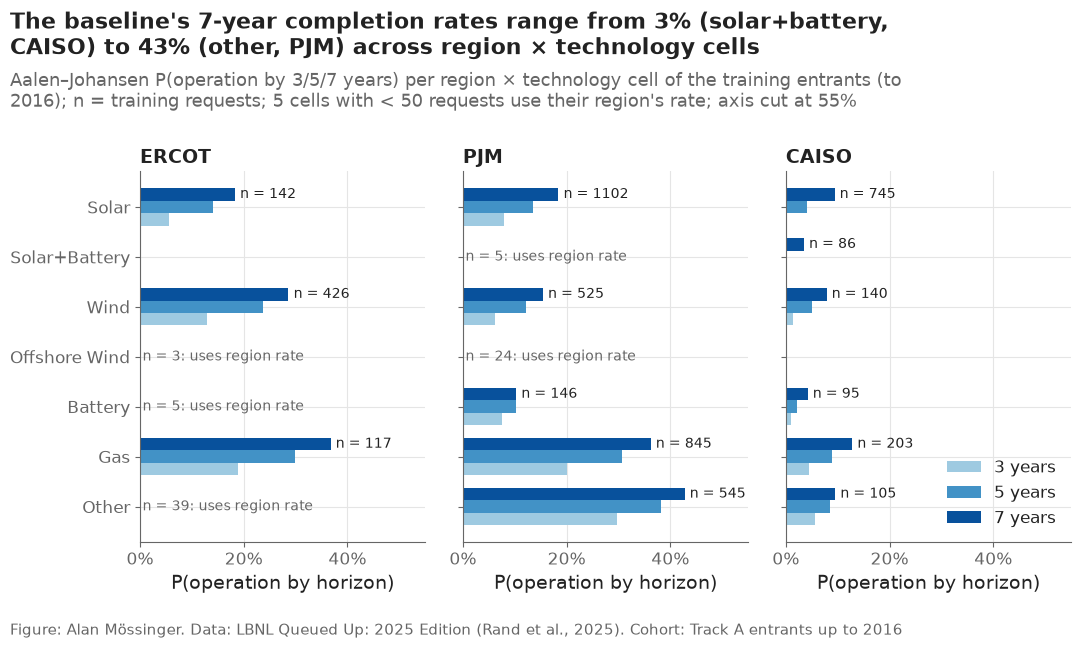

,region,tech,3,5,7,cell,n_train
1685,CAISO,Gas,0.044,0.089,0.128,region × technology,203
1682,CAISO,Other,0.057,0.086,0.095,region × technology,105
1694,CAISO,Wind,0.014,0.050,0.079,region × technology,140
1683,CAISO,Solar,0.003,0.042,0.094,region × technology,745
1690,CAISO,Battery,0.011,0.021,0.042,region × technology,95
35223,CAISO,Solar+Battery,0.000,0.000,0.035,region × technology,86
29829,ERCOT,Gas,0.188,0.299,0.368,region × technology,117
29802,ERCOT,Wind,0.129,0.237,0.286,region × technology,426
32402,ERCOT,Other,0.122,0.223,0.273,region,39
32532,ERCOT,Offshore Wind,0.122,0.223,0.273,region,3


In [3]:
baseline_final = survival_tools.baseline_cif(final, final.drop_duplicates(["region", "tech"]), HORIZONS)
cells = final.drop_duplicates(["region", "tech"])[["region", "tech"]].join(baseline_final)
cells["n_train"] = cells.apply(lambda r: int(((final["region"] == r["region"]) & (final["tech"] == r["tech"])).sum()), axis=1)
cells = cells.sort_values(["region", 5], ascending=[True, False])
cells.to_csv(paths.RESULTS / "baseline_cells.csv", index=False)

tech_order = [t for t in config.TECH_COLORS if t in set(cells["tech"])][::-1]
fig, axes = plt.subplots(1, 3, sharey=True)
shades = {3: "#9ECAE1", 5: "#4292C6", 7: "#08519C"}  # one hue, light → dark for longer horizons
for ax, region in zip(axes, TRACK_A):
    part = cells[cells["region"] == region].set_index("tech")
    for y, tech in enumerate(tech_order):
        if tech not in part.index:
            continue
        row = part.loc[tech]
        if row["cell"] == "region":
            ax.text(0.005, y, f"n = {row['n_train']}: uses region rate", va="center", fontsize=10, color=plots.MUTED)
            continue
        for offset, h in zip([-0.25, 0, 0.25], HORIZONS):
            ax.barh(y + offset, row[h], height=0.25, color=shades[h], label=f"{h} years" if y == 0 else None)
        ax.text(row[7] + 0.01, y + 0.25, f"n = {row['n_train']}", va="center", fontsize=10)
    ax.set_title(region)
    ax.set_xlim(0, 0.55)
    ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
    ax.set_xlabel("P(operation by horizon)")
axes[0].set_yticks(range(len(tech_order)), tech_order)
handles = [plt.Rectangle((0, 0), 1, 1, color=shades[h]) for h in HORIZONS]
axes[-1].legend(handles, [f"{h} years" for h in HORIZONS], loc="lower right")
fallback = cells[cells["cell"] == "region"]
own = cells[cells["cell"] == "region × technology"]
lowest, highest = own.loc[own[7].idxmin()], own.loc[own[7].idxmax()]
plots.finish(fig,
             f"The baseline's 7-year completion rates range from {lowest[7]:.0%} ({lowest['tech'].lower()}, "
             f"{lowest['region']}) to {highest[7]:.0%} ({highest['tech'].lower()}, {highest['region']}) across "
             "region × technology cells",
             "Aalen–Johansen P(operation by 3/5/7 years) per region × technology cell of the training entrants "
             f"(to {config.TRAIN_MAX_YEAR}); n = training requests; {len(fallback)} cells with < 50 requests use "
             "their region's rate; axis cut at 55%",
             f"Track A entrants up to {config.TRAIN_MAX_YEAR}")
save(fig, "05_01_baseline_cells", "Baseline P(operation by 3, 5 and 7 years) for each region × technology cell of the training data.")
plt.show()
cells.round(3)

**Reading this.** The baseline gives each request the historical P(operation by t) of its region × technology cell. By 7 years these rates run from 3.5% (solar+battery in CAISO) to 42.8% ("Other" in PJM). Five cells have fewer than 50 training requests and use their region's rate: "Other", offshore wind and batteries in ERCOT, solar+battery and offshore wind in PJM. This is a demanding benchmark rather than a straw man: it already knows region and technology, the two strongest signals in notebook 03.

## 3. Tuning the penalty on the 2016 cohort

Each cause-specific model is fitted on entrants up to 2015 with a ridge
penalty from a grid and scored by its average log partial likelihood on the
2016 entrants; the best penalty per cause is kept.

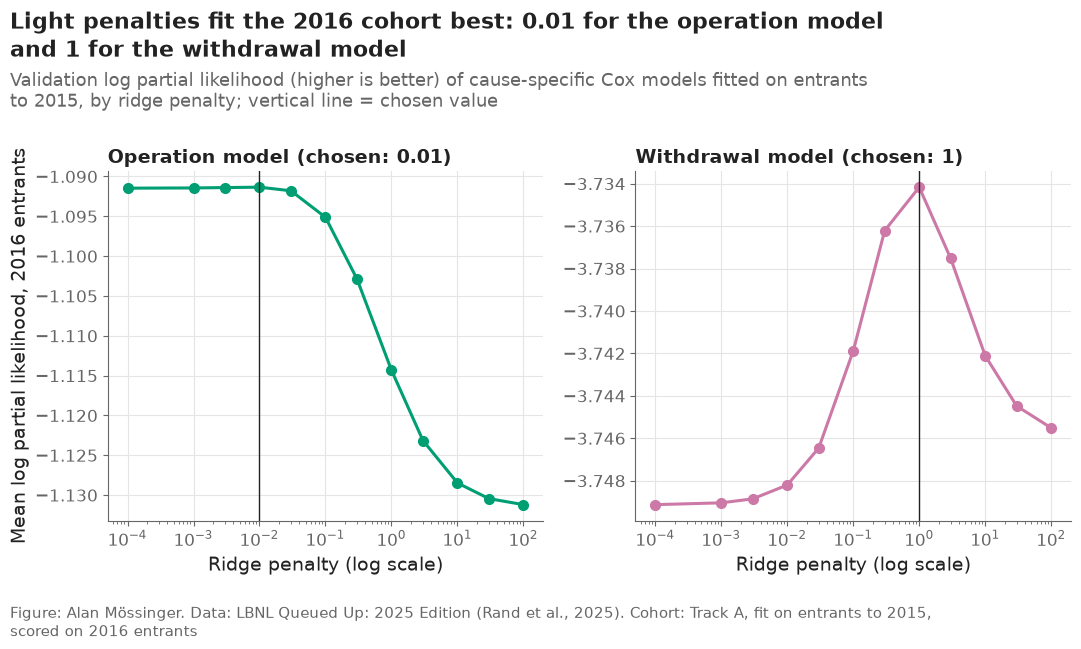

cause,operation,withdrawal
penalizer,,
0.0001,-1.0915,-3.7491
0.0010,-1.0914,-3.7490
0.0030,-1.0914,-3.7489
0.0100,-1.0913,-3.7482
0.0300,-1.0918,-3.7465
0.1000,-1.0951,-3.7419
0.3000,-1.1029,-3.7362
1.0000,-1.1143,-3.7342
3.0000,-1.1231,-3.7375


In [4]:
tuning_rows = []
for cause in CAUSES:
    valid_data = cox_frame(valid, cause)
    valid_data = valid_data[valid_data["T"] > valid_data["entry"]]
    for penalizer in PENALIZERS:
        model = fit_cox(tune, cause, penalizer)
        tuning_rows.append({"cause": cause, "penalizer": penalizer,
                            "validation_log_likelihood": model.score(valid_data, scoring_method="log_likelihood")})
tuning = pd.DataFrame(tuning_rows)
tuning.to_csv(paths.RESULTS / "cox_penalizer_tuning.csv", index=False)
best = tuning.loc[tuning.groupby("cause")["validation_log_likelihood"].idxmax()].set_index("cause")["penalizer"]

fig, axes = plt.subplots(1, 2)
for ax, cause in zip(axes, CAUSES):
    part = tuning[tuning["cause"] == cause]
    ax.plot(part["penalizer"], part["validation_log_likelihood"], color=config.OUTCOME_COLORS[cause], marker="o")
    ax.axvline(best[cause], color=plots.INK, linewidth=1)
    ax.set_xscale("log")
    ax.set_title(f"{cause.capitalize()} model (chosen: {best[cause]:g})")
    ax.set_xlabel("Ridge penalty (log scale)")
axes[0].set_ylabel("Mean log partial likelihood, 2016 entrants")
plots.finish(fig,
             f"Light penalties fit the 2016 cohort best: {best['operation']:g} for the operation model and "
             f"{best['withdrawal']:g} for the withdrawal model",
             "Validation log partial likelihood (higher is better) of cause-specific Cox models fitted on entrants to "
             "2015, by ridge penalty; vertical line = chosen value",
             "Track A, fit on entrants to 2015, scored on 2016 entrants")
save(fig, "05_02_penalizer_tuning", "Validation log partial likelihood of the cause-specific Cox models by ridge penalty.")
plt.show()
tuning.pivot(index="penalizer", columns="cause", values="validation_log_likelihood").round(4)

**Reading this.** The validation log partial likelihood barely moves for the operation model until the penalty passes 0.03 (−1.0913 at the best value, 0.01), so the operation coefficients are not being overfitted. The withdrawal model prefers a much stronger penalty (best 1.0, an interior optimum of the extended grid): its covariates explain little about when projects withdraw, and shrinking them towards zero predicts the 2016 cohort better.

## 4. The fitted models: hazard ratios

Final fits on entrants up to 2016 with the chosen penalties. A hazard ratio
above 1 means a higher yearly chance of that exit, other covariates equal;
operation and withdrawal are separate models, so a characteristic can raise
both (it speeds the queue up) or move them in opposite directions.

In [5]:
models = {cause: fit_cox(final, cause, best[cause]) for cause in CAUSES}
sensitivity = {cause: fit_cox(final, cause, best[cause], delayed=False) for cause in CAUSES}
hr_rows = []
for version, fitted in [("main (ERCOT delayed entry)", models), ("sensitivity (dates as recorded)", sensitivity)]:
    for cause, model in fitted.items():
        s = model.summary
        hr_rows.append(pd.DataFrame({"version": version, "cause": cause, "covariate": s.index,
                                     "hazard_ratio": s["exp(coef)"].to_numpy(),
                                     "ci_low": s["exp(coef) lower 95%"].to_numpy(),
                                     "ci_high": s["exp(coef) upper 95%"].to_numpy(), "p": s["p"].to_numpy()}))
hazard_ratios = pd.concat(hr_rows, ignore_index=True)
hazard_ratios.to_csv(paths.RESULTS / "cox_hazard_ratios.csv", index=False)
main_hr = hazard_ratios[hazard_ratios["version"].str.startswith("main")]
main_hr.pivot(index="covariate", columns="cause", values=["hazard_ratio", "p"]).round(3)

hazard_ratio                    p           
cause                 operation withdrawal operation withdrawal
covariate                                                      
congestion_rank           0.614      0.901     0.001      0.016
log_congestion_gw         0.991      1.139     0.905      0.000
q_year_5                  0.843      1.020     0.001      0.154
region_CAISO              0.523      1.098     0.000      0.000
region_ERCOT              1.658      0.910     0.032      0.216
service_ERIS              0.698      1.022     0.001      0.538
service_missing           1.075      1.165     0.684      0.000
size_100–<200             0.693      0.923     0.000      0.023
size_200–<500             0.514      0.993     0.000      0.839
size_5–<20                1.339      1.027     0.000      0.336
size_<5                   1.852      1.060     0.000      0.092
size_≥500                 0.306      1.101     0.000      0.009
tech_Battery              0.676      1.021     0.046      0.683
tech_Gas                  2.564      0.950     0.000      0.067
tech_Offshore Wind        0.173      0.990     0.024      0.947
tech_Other                1.743      0.925     0.000      0.019
tech_Solar+Battery        0.673      0.546     0.070      0.000
tech_Wind                 0.666      0.923     0.000      0.010

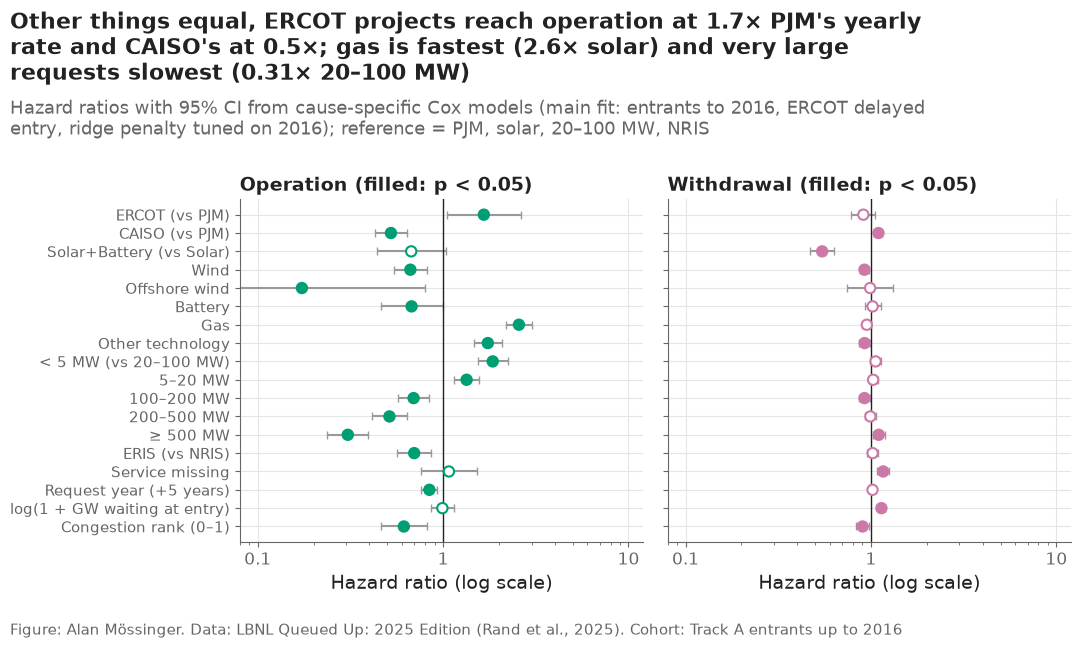

In [6]:
LABELS = {"region_ERCOT": "ERCOT (vs PJM)", "region_CAISO": "CAISO (vs PJM)",
          "tech_Solar+Battery": "Solar+Battery (vs Solar)", "tech_Wind": "Wind", "tech_Offshore Wind": "Offshore wind",
          "tech_Battery": "Battery", "tech_Gas": "Gas", "tech_Other": "Other technology",
          "size_<5": "< 5 MW (vs 20–100 MW)", "size_5–<20": "5–20 MW", "size_100–<200": "100–200 MW",
          "size_200–<500": "200–500 MW", "size_≥500": "≥ 500 MW", "service_ERIS": "ERIS (vs NRIS)",
          "service_missing": "Service missing",
          "q_year_5": "Request year (+5 years)", "log_congestion_gw": "log(1 + GW waiting at entry)",
          "congestion_rank": "Congestion rank (0–1)"}
order = list(LABELS)
fig, axes = plt.subplots(1, 2, sharey=True)
for ax, cause in zip(axes, CAUSES):
    part = main_hr[main_hr["cause"] == cause].set_index("covariate").reindex(order)
    y = np.arange(len(order))[::-1]
    significant = part["p"] < 0.05
    ax.errorbar(part["hazard_ratio"], y, xerr=[part["hazard_ratio"] - part["ci_low"], part["ci_high"] - part["hazard_ratio"]],
                fmt="none", color="#999999", linewidth=1.5, capsize=3)
    ax.scatter(part["hazard_ratio"], y, s=55, zorder=3,
               color=np.where(significant, config.OUTCOME_COLORS[cause], "white"),
               edgecolors=config.OUTCOME_COLORS[cause], linewidths=1.5)
    ax.axvline(1, color=plots.INK, linewidth=1)
    ax.set_xscale("log")
    ax.set_xlim(0.08, 12)
    ax.xaxis.set_major_formatter(lambda x, _: f"{x:g}")
    ax.set_title(f"{cause.capitalize()} (filled: p < 0.05)")
    ax.set_xlabel("Hazard ratio (log scale)")
axes[0].set_yticks(np.arange(len(order))[::-1], [LABELS[c] for c in order], fontsize=11)
op = main_hr[main_hr["cause"] == "operation"].set_index("covariate")["hazard_ratio"]
plots.finish(fig,
             f"Other things equal, ERCOT projects reach operation at {op['region_ERCOT']:.1f}× PJM's yearly rate and "
             f"CAISO's at {op['region_CAISO']:.1f}×; gas is fastest ({op['tech_Gas']:.1f}× solar) and very large "
             f"requests slowest ({op['size_≥500']:.2f}× 20–100 MW)",
             "Hazard ratios with 95% CI from cause-specific Cox models (main fit: entrants to 2016, ERCOT delayed "
             "entry, ridge penalty tuned on 2016); reference = PJM, solar, 20–100 MW, NRIS",
             f"Track A entrants up to {config.TRAIN_MAX_YEAR}")
save(fig, "05_03_hazard_ratios", "Hazard ratios of the cause-specific Cox models for operation and withdrawal (forest plot).")
plt.show()

**Reading this.** For reaching operation, other things equal: ERCOT projects have 1.66× PJM's yearly rate (95% CI 1.04–2.64) and CAISO projects 0.52× (0.43–0.64). Gas runs at 2.56× solar's rate and "Other" at 1.74×; wind (0.67×), batteries (0.68×) and offshore wind (0.17×) are slower than solar. Size has a clear gradient: under 5 MW 1.85×, 5–20 MW 1.34×, then 0.69×, 0.51× and 0.31× for the three classes above 100 MW, all against 20–100 MW. Energy-only (ERIS) requests are slower (0.70×). Each later 5 years of request date lowers the rate (0.84×). Congestion in GW adds nothing once request year is in the model (0.99×, p = 0.90), but a request entering a queue that is crowded *relative to its region's history* is slower (rank 0.61× from least to most crowded). For withdrawal, the covariates matter far less, as the tuning suggested: hybrids (0.55×) and wind (0.92×) withdraw more slowly, CAISO slightly faster (1.10×), and more GW waiting at entry speeds withdrawal (1.14× per log unit). The developer-facing message: a small gas or "Other" project in ERCOT is the fastest profile; a large storage-heavy project in CAISO the slowest.

## 5. Do the hazard ratios have the expected signs?

PLAN.md's check: for operation, ERCOT > PJM > CAISO, and requests of 20 MW or
more are slower than smaller ones.

In [7]:
op = main_hr[main_hr["cause"] == "operation"].set_index("covariate")
sign_checks = pd.DataFrame([
    ("ERCOT faster than PJM (HR > 1)", op.loc["region_ERCOT", "hazard_ratio"], op.loc["region_ERCOT", "hazard_ratio"] > 1),
    ("CAISO slower than PJM (HR < 1)", op.loc["region_CAISO", "hazard_ratio"], op.loc["region_CAISO", "hazard_ratio"] < 1),
    ("< 5 MW faster than 20–100 MW", op.loc["size_<5", "hazard_ratio"], op.loc["size_<5", "hazard_ratio"] > 1),
    ("5–20 MW faster than 20–100 MW", op.loc["size_5–<20", "hazard_ratio"], op.loc["size_5–<20", "hazard_ratio"] > 1),
], columns=["check", "hazard_ratio", "passed"])
sign_checks

,check,hazard_ratio,passed
0,ERCOT faster than PJM (HR > 1),1.658347,True
1,CAISO slower than PJM (HR < 1),0.523311,True
2,< 5 MW faster than 20–100 MW,1.851728,True
3,5–20 MW faster than 20–100 MW,1.339173,True


**Reading this.** All four of the plan's sign checks pass: ERCOT is faster than PJM and CAISO slower (1.66 and 0.52), and both size classes under 20 MW are faster than 20–100 MW (1.85 and 1.34). Under the as-recorded dates the ERCOT ratio would be 0.64 and the check would fail (section 7) — the stamped withdrawals distort exactly this coefficient.

## 6. Proportional hazards: diagnostics

A Cox hazard ratio is one number for the whole wait, which is only fair if
the effect is roughly constant over time in the queue. The test correlates
each covariate's scaled Schoenfeld residuals with (rank-transformed) time;
small p-values mean the effect changes with time. It runs on the as-recorded
fit (decision #25).

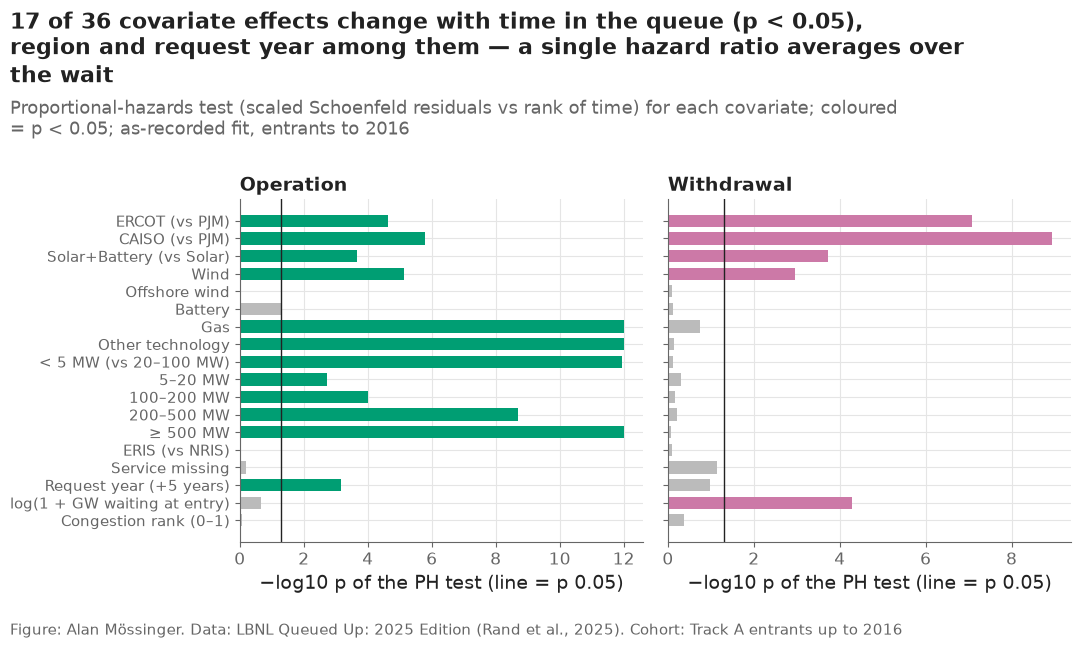

cause,operation,withdrawal
covariate,,
region_ERCOT,0.0000,0.0000
region_CAISO,0.0000,0.0000
tech_Solar+Battery,0.0002,0.0002
tech_Wind,0.0000,0.0011
tech_Offshore Wind,0.9866,0.7981
tech_Battery,0.0513,0.7762
tech_Gas,0.0000,0.1780
tech_Other,0.0000,0.7230
size_<5,0.0000,0.7490


In [8]:
ph_rows, residuals = [], {}
for cause in CAUSES:
    data = cox_frame(final, cause, delayed=False).drop(columns="entry")
    test_result = proportional_hazard_test(sensitivity[cause], data, time_transform="rank")
    table = test_result.summary.reset_index().rename(columns={"index": "covariate"})
    table["cause"] = cause
    ph_rows.append(table[["cause", "covariate", "test_statistic", "p"]])
    residuals[cause] = (sensitivity[cause].compute_residuals(data, kind="scaled_schoenfeld"), data)
ph_tests = pd.concat(ph_rows, ignore_index=True)
ph_tests.to_csv(paths.RESULTS / "cox_ph_tests.csv", index=False)

fig, axes = plt.subplots(1, 2, sharey=True)
for ax, cause in zip(axes, CAUSES):
    part = ph_tests[ph_tests["cause"] == cause].set_index("covariate").reindex(order)
    y = np.arange(len(order))[::-1]
    score = -np.log10(part["p"].clip(lower=1e-12))
    ax.barh(y, score, color=np.where(part["p"] < 0.05, config.OUTCOME_COLORS[cause], "#BBBBBB"), height=0.7)
    ax.axvline(-np.log10(0.05), color=plots.INK, linewidth=1)
    ax.set_title(cause.capitalize())
    ax.set_xlabel("−log10 p of the PH test (line = p 0.05)")
axes[0].set_yticks(np.arange(len(order))[::-1], [LABELS[c] for c in order], fontsize=11)
violations = ph_tests[ph_tests["p"] < 0.05]
plots.finish(fig,
             f"{len(violations)} of {len(ph_tests)} covariate effects change with time in the queue (p < 0.05), "
             "region and request year among them — a single hazard ratio averages over the wait",
             "Proportional-hazards test (scaled Schoenfeld residuals vs rank of time) for each covariate; coloured = "
             "p < 0.05; as-recorded fit, entrants to 2016",
             f"Track A entrants up to {config.TRAIN_MAX_YEAR}")
save(fig, "05_04_ph_tests", "Proportional-hazards test p-values for each covariate of the two cause-specific Cox models.")
plt.show()
ph_tests.pivot(index="covariate", columns="cause", values="p").reindex(order).round(4)

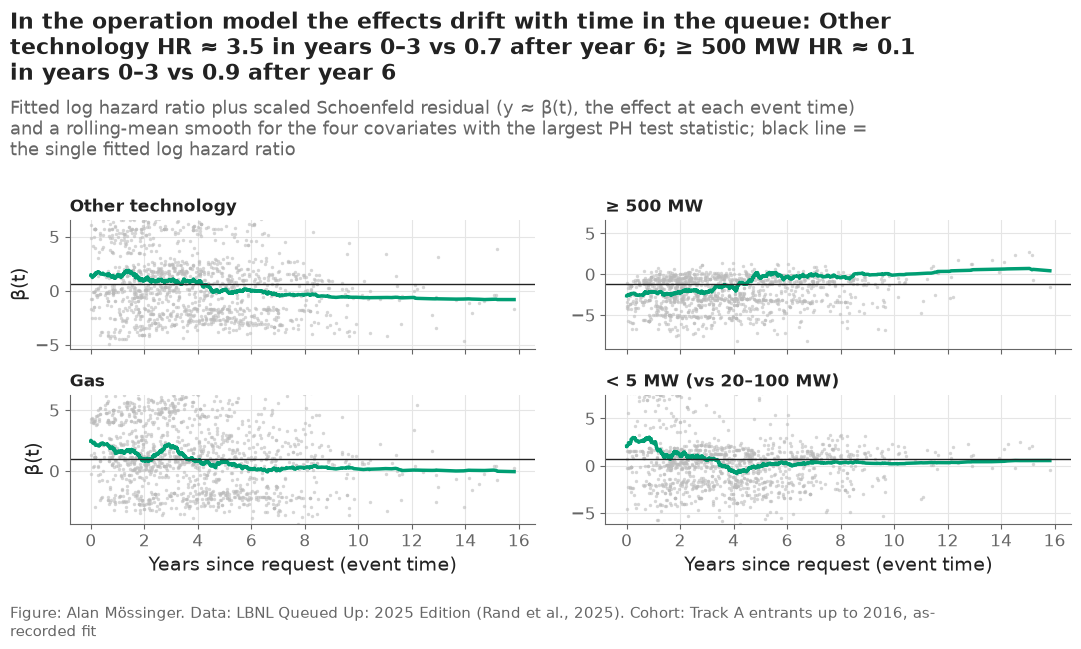

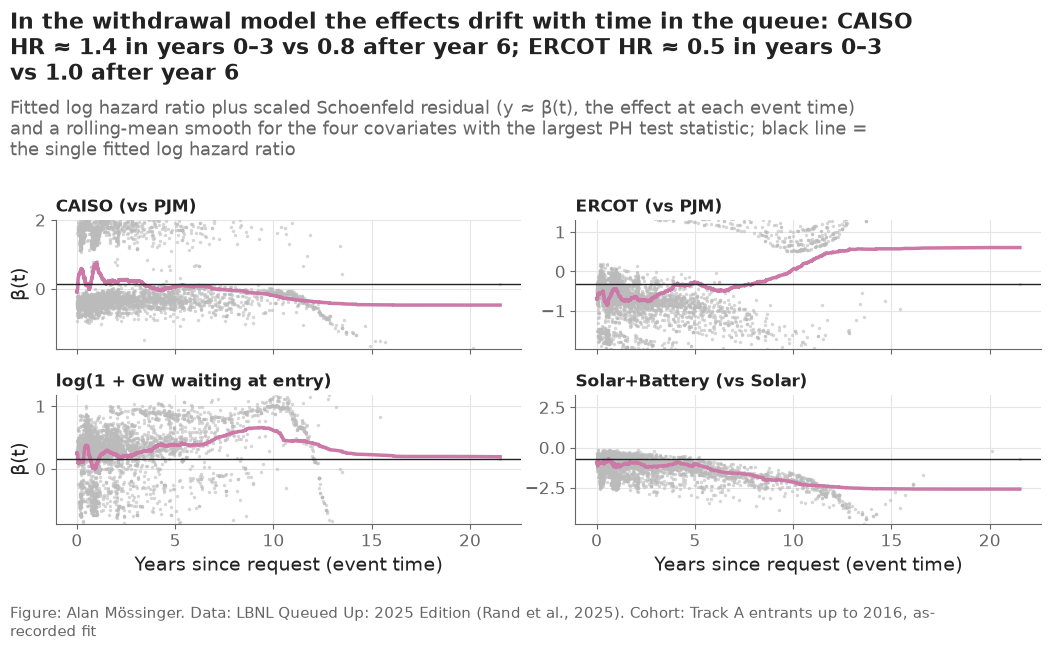

,cause,covariate,hr_years_0_3,hr_after_year_6,hr_fitted
0,operation,tech_Other,3.51,0.72,1.79
1,operation,size_≥500,0.11,0.91,0.29
2,operation,tech_Gas,4.72,1.18,2.59
3,operation,size_<5,4.45,1.35,1.98
4,withdrawal,region_CAISO,1.38,0.81,1.13
5,withdrawal,region_ERCOT,0.53,0.99,0.72
6,withdrawal,log_congestion_gw,1.20,1.53,1.16
7,withdrawal,tech_Solar+Battery,0.37,0.13,0.48


In [9]:
drift_rows = []
for cause in CAUSES:
    scaled, data = residuals[cause]
    worst = (ph_tests[ph_tests["cause"] == cause].sort_values("test_statistic", ascending=False)["covariate"].head(4).tolist())
    times = data.loc[scaled.index, "T"].to_numpy()
    fig, axes = plt.subplots(2, 2, sharex=True)
    for ax, covariate in zip(axes.flat, worst):
        coef = sensitivity[cause].params_[covariate]
        values = scaled[covariate].to_numpy() + coef  # lifelines' scaled residuals average 0; β(t) ≈ β + residual
        ax.scatter(times, values, s=6, color="#BBBBBB", alpha=0.6, linewidths=0)
        order_t = np.argsort(times)
        window = max(25, len(times) // 10)  # rolling mean over ~10% of the events, in time order
        smooth = pd.Series(values[order_t]).rolling(window, center=True, min_periods=window // 2).mean()
        ax.plot(times[order_t], smooth, color=config.OUTCOME_COLORS[cause], linewidth=2.5)
        ax.axhline(coef, color=plots.INK, linewidth=1)
        ax.set_ylim(coef - 4 * values.std() / 2, coef + 4 * values.std() / 2)
        ax.set_title(LABELS[covariate], fontsize=12)
    for ax in axes[-1]:
        ax.set_xlabel("Years since request (event time)")
    for ax in axes[:, 0]:
        ax.set_ylabel("β(t)")
    params = sensitivity[cause].params_
    early = {c: np.exp(params[c] + scaled.loc[times < 3, c].mean()) for c in worst}
    late = {c: np.exp(params[c] + scaled.loc[times >= 6, c].mean()) for c in worst}
    drift_rows.extend({"cause": cause, "covariate": c, "hr_years_0_3": early[c], "hr_after_year_6": late[c],
                       "hr_fitted": np.exp(sensitivity[cause].params_[c])} for c in worst)
    plots.finish(fig,
                 f"In the {cause} model the effects drift with time in the queue: "
                 + "; ".join(f"{LABELS[c].split(' (')[0]} HR ≈ {early[c]:.1f} in years 0–3 vs {late[c]:.1f} after year 6"
                             for c in worst[:2]),
                 f"Fitted log hazard ratio plus scaled Schoenfeld residual (y ≈ β(t), the effect at each event time) and a rolling-mean smooth for the four "
                 f"covariates with the largest PH test statistic; black line = the single fitted log hazard ratio",
                 f"Track A entrants up to {config.TRAIN_MAX_YEAR}, as-recorded fit")
    save(fig, f"diag_schoenfeld_{cause}",
         f"Scaled Schoenfeld residuals over time for the covariates with the strongest evidence of non-proportional "
         f"hazards in the {cause} model.")
    plt.show()
pd.DataFrame(drift_rows).round(2)

**Reading this.** 17 of 36 covariate effects fail the proportional-hazards test at p < 0.05, including region, every size class and the main technologies in the operation model. The drift has a consistent shape: what makes a project fast does so early. Gas runs at about 4.7× solar's rate in its first three years but about 1.2× after year 6; "Other" goes from 3.5× to 0.7×; requests under 5 MW from 4.5× to 1.4×; and requests of 500 MW or more start at about 0.11× and are roughly even (0.91×) after year 6. In the withdrawal model, CAISO's extra withdrawal risk is concentrated early (1.38× in years 0–3) and ERCOT's lower risk early (0.53×). So the single hazard ratios above are averages over the wait, fine for ranking which attributes matter but too coarse for timing. Notebook 06 handles this by giving every year in the queue its own effect and letting the effects vary with it.

## 7. Sensitivity: ERCOT dates as recorded

The same models fitted with ERCOT's stamped withdrawals taken at face value.
Covariates whose hazard ratio barely moves are robust to the choice in
decision #21.

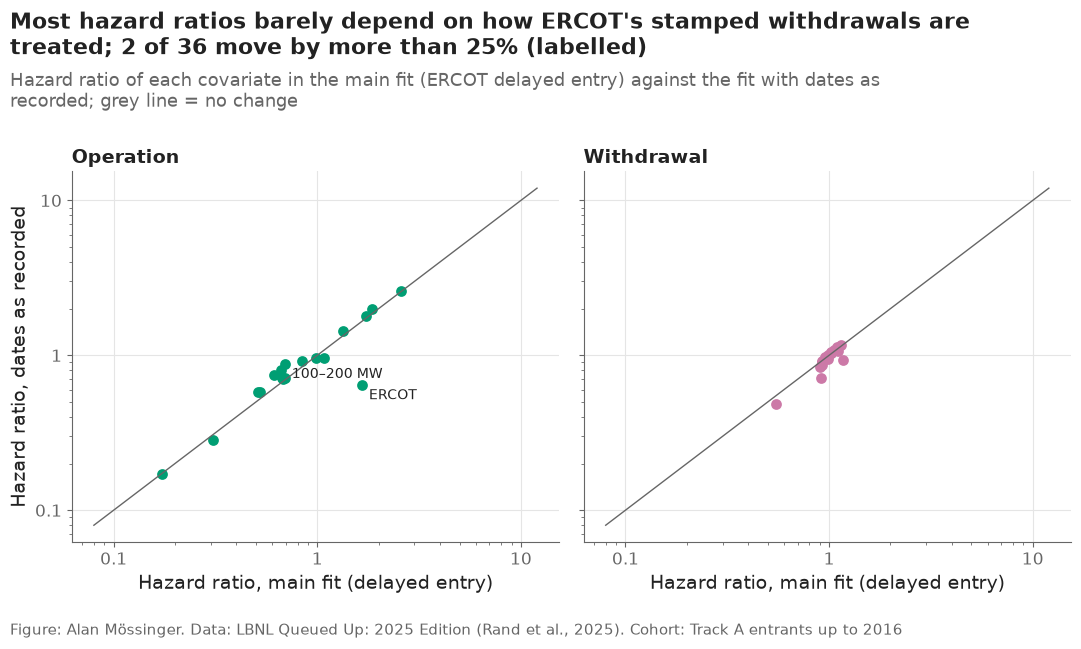

main  as_recorded  ratio
cause      covariate                                    
operation  congestion_rank     0.614        0.741  1.206
           log_congestion_gw   0.991        0.961  0.969
           q_year_5            0.843        0.917  1.087
           region_CAISO        0.523        0.577  1.103
           region_ERCOT        1.658        0.640  0.386
           service_ERIS        0.698        0.716  1.025
           service_missing     1.075        0.956  0.889
           size_100–<200       0.693        0.878  1.267
           size_200–<500       0.514        0.577  1.123
           size_5–<20          1.339        1.440  1.076
           size_<5             1.852        1.976  1.067
           size_≥500           0.306        0.286  0.933
           tech_Battery        0.676        0.707  1.045
           tech_Gas            2.564        2.591  1.010
           tech_Offshore Wind  0.173        0.172  0.992
           tech_Other          1.743        1.791  1.028
           tech_Solar+Battery  0.673        0.711  1.056
           tech_Wind           0.666        0.807  1.212
withdrawal congestion_rank     0.901        0.841  0.934
           log_congestion_gw   1.139        1.163  1.021
           q_year_5            1.020        1.034  1.014
           region_CAISO        1.098        1.133  1.032
           region_ERCOT        0.910        0.718  0.789
           service_ERIS        1.022        1.028  1.006
           service_missing     1.165        0.926  0.795
           size_100–<200       0.923        0.912  0.988
           size_200–<500       0.993        0.942  0.948
           size_5–<20          1.027        1.055  1.027
           size_<5             1.060        1.086  1.024
           size_≥500           1.101        1.062  0.964
           tech_Battery        1.021        1.028  1.007
           tech_Gas            0.950        0.975  1.026
           tech_Offshore Wind  0.990        1.012  1.022
           tech_Other          0.925        0.914  0.987
           tech_Solar+Battery  0.546        0.482  0.883
           tech_Wind           0.923        0.871  0.944

In [10]:
compare = hazard_ratios.pivot_table(index=["cause", "covariate"], columns="version", values="hazard_ratio")
compare.columns = ["main", "as_recorded"]
compare["ratio"] = compare["as_recorded"] / compare["main"]
fig, axes = plt.subplots(1, 2, sharex=True, sharey=True)
for ax, cause in zip(axes, CAUSES):
    part = compare.loc[cause]
    ax.scatter(part["main"], part["as_recorded"], color=config.OUTCOME_COLORS[cause], s=60, edgecolors="white")
    ax.plot([0.08, 12], [0.08, 12], color=plots.MUTED, linewidth=1)
    moved = part[(part["ratio"] - 1).abs() > 0.25]
    for covariate, row in moved.iterrows():
        ax.annotate(LABELS[covariate].split(" (")[0], (row["main"], row["as_recorded"]), xytext=(5, -10),
                    textcoords="offset points", fontsize=10)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_title(cause.capitalize())
    ax.set_xlabel("Hazard ratio, main fit (delayed entry)")
    for axis in (ax.xaxis, ax.yaxis):
        axis.set_major_formatter(lambda v, _: f"{v:g}")
axes[0].set_ylabel("Hazard ratio, dates as recorded")
n_moved = int(((compare["ratio"] - 1).abs() > 0.25).sum())
plots.finish(fig,
             f"Most hazard ratios barely depend on how ERCOT's stamped withdrawals are treated; {n_moved} of "
             f"{len(compare)} move by more than 25% (labelled)",
             "Hazard ratio of each covariate in the main fit (ERCOT delayed entry) against the fit with dates as "
             "recorded; grey line = no change",
             f"Track A entrants up to {config.TRAIN_MAX_YEAR}")
save(fig, "05_05_sensitivity_ercot_dates", "Hazard ratios of the main Cox fit against the fit with ERCOT's withdrawal dates as recorded.")
plt.show()
compare.round(3)

**Reading this.** Only 2 of 36 hazard ratios move by more than 25% when ERCOT's stamped withdrawals are taken at face value, and the big one is the ERCOT effect itself: 1.66 under delayed entry against 0.64 as recorded. The as-recorded number cannot be right — it would say ERCOT builds more slowly than PJM, against the Aalen–Johansen curves of notebook 03, which are unaffected by the stamp. The other move is 100–200 MW (0.69 → 0.88). Everything a developer would read off the table except the ERCOT term is robust to this data problem.

## 8. A check on the 2016 cohort

Validation outcomes may be used: the 2016 entrants were held out of the tuning
fits and are not the test set. Mean predicted P(operation by t) of the
baseline and of the Cox models (both fitted on entrants to 2015) against the
observed Aalen–Johansen estimate, by region.

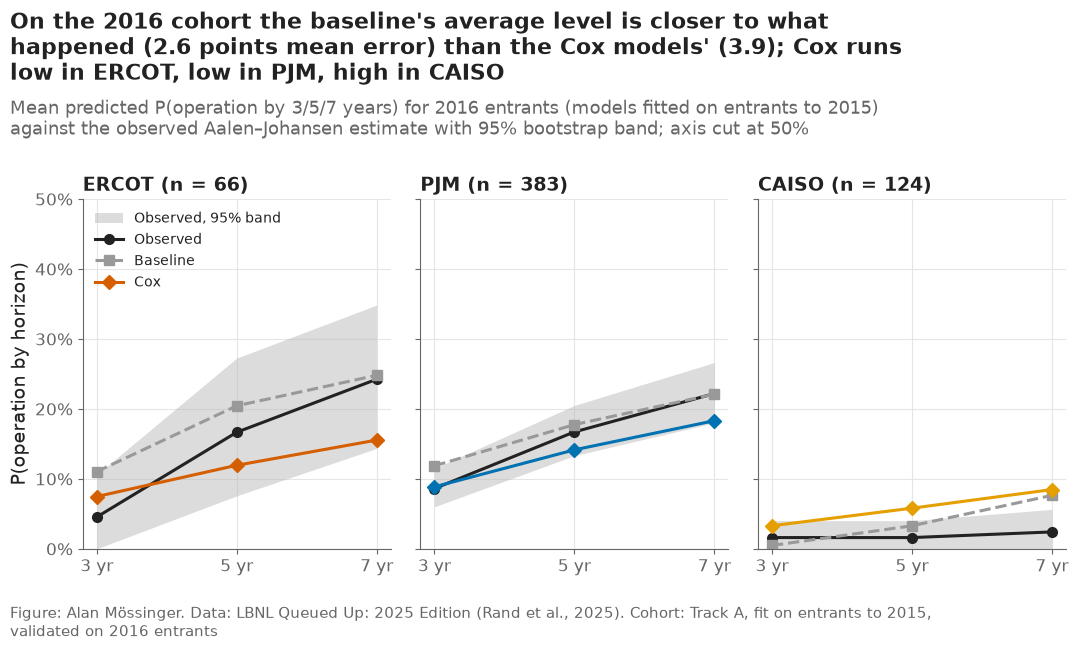

,region,n,horizon,observed,low,high,baseline,cox
0,ERCOT,66,3,0.045,0.000,0.106,0.110,0.075
1,ERCOT,66,5,0.167,0.076,0.273,0.205,0.119
2,ERCOT,66,7,0.242,0.144,0.348,0.248,0.155
3,PJM,383,3,0.086,0.060,0.115,0.119,0.089
4,PJM,383,5,0.167,0.133,0.205,0.178,0.141
5,PJM,383,7,0.222,0.180,0.266,0.221,0.183
6,CAISO,124,3,0.016,0.000,0.040,0.005,0.033
7,CAISO,124,5,0.016,0.000,0.040,0.033,0.058
8,CAISO,124,7,0.024,0.000,0.056,0.076,0.085


In [11]:
baseline_tune = survival_tools.baseline_cif(tune, valid, HORIZONS)
tune_models = {cause: fit_cox(tune, cause, best[cause]) for cause in CAUSES}
cox_valid = survival_tools.cause_specific_cif(tune_models["operation"], tune_models["withdrawal"],
                                              survival_tools.cox_design(valid), HORIZONS)
val_rows = []
for i, region in enumerate(TRACK_A):
    part = valid[valid["region"] == region]
    fit = survival_tools.aalen_johansen(part["duration_years"], part["event"], HORIZONS)
    band = survival_tools.bootstrap_bands(part["duration_years"], part["event"], HORIZONS, n_boot=500, seed=500 + i)
    for j, h in enumerate(HORIZONS):
        val_rows.append({"region": region, "n": len(part), "horizon": h, "observed": fit["cif_operation"].iloc[j],
                         "low": band["cif_operation_low"].iloc[j], "high": band["cif_operation_high"].iloc[j],
                         "baseline": baseline_tune.loc[part.index, h].mean(), "cox": cox_valid.loc[part.index, h].mean()})
validation = pd.DataFrame(val_rows)
validation.to_csv(paths.RESULTS / "cox_validation_calibration.csv", index=False)

fig, axes = plt.subplots(1, 3, sharey=True)
for ax, region in zip(axes, TRACK_A):
    part = validation[validation["region"] == region]
    ax.fill_between(part["horizon"], part["low"], part["high"], color="#BBBBBB", alpha=0.5, linewidth=0,
                    label="Observed, 95% band")
    ax.plot(part["horizon"], part["observed"], color=plots.INK, marker="o", label="Observed")
    ax.plot(part["horizon"], part["baseline"], color="#999999", marker="s", linestyle="--", label="Baseline")
    ax.plot(part["horizon"], part["cox"], color=plots.region_color(region), marker="D", label="Cox")
    ax.set_title(f"{region} (n = {part['n'].iloc[0]})")
    ax.set_xticks(HORIZONS, [f"{h} yr" for h in HORIZONS])
    ax.set_ylim(0, 0.5)
    ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
axes[0].set_ylabel("P(operation by horizon)")
axes[0].legend(loc="upper left", fontsize=10)
gap = validation.assign(cox_err=(validation["cox"] - validation["observed"]).abs(),
                        base_err=(validation["baseline"] - validation["observed"]).abs())
direction = (validation["cox"] - validation["observed"]).groupby(validation["region"]).mean()
plots.finish(fig,
             f"On the 2016 cohort the baseline's average level is closer to what happened "
             f"({100 * gap['base_err'].mean():.1f} points mean error) than the Cox models' "
             f"({100 * gap['cox_err'].mean():.1f}); Cox runs "
             + ", ".join(f"{'low' if direction[r] < 0 else 'high'} in {r}" for r in TRACK_A),
             "Mean predicted P(operation by 3/5/7 years) for 2016 entrants (models fitted on entrants to 2015) against "
             "the observed Aalen–Johansen estimate with 95% bootstrap band; axis cut at 50%",
             "Track A, fit on entrants to 2015, validated on 2016 entrants")
save(fig, "05_06_validation_check", "Mean predicted versus observed P(operation by 3, 5 and 7 years) on the 2016 validation cohort, by region.")
plt.show()
validation.round(3)

**Reading this.** On the 2016 cohort the baseline's average level is closer to what happened than the Cox models' — 2.6 against 3.9 points of mean absolute error, and the baseline is closer in every region (ERCOT 3.6 vs 5.4, PJM 1.5 vs 2.2, CAISO 2.7 vs 4.0). The Cox models run low for ERCOT and PJM at 5 and 7 years (ERCOT 11.9% vs an observed 16.7% at 5 years) and high for CAISO, whose 2016 entrants reached only 2.4% by seven years. Two causes are visible: the request-year trend (0.84× per 5 years) pulls predictions down, and ERCOT's effect rests on 125 post-window requests. This compares averages only; whether Cox *ranks* projects better than the baseline is the question notebook 08 answers on the test set. With 66 ERCOT and 124 CAISO requests, the bands are wide.

## 9. What the model says about a typical request

P(operation by t) over seven years for one reference request — solar,
20–100 MW, NRIS, requested in 2016 at its region's median congestion — in
each region, from the final Cox models.

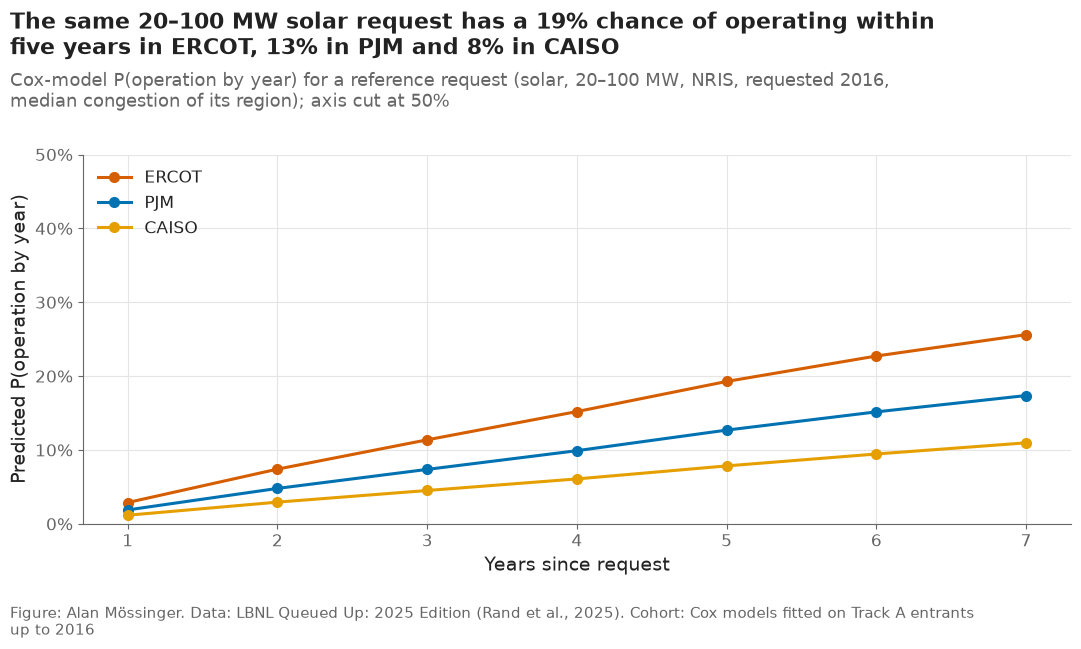

,1,2,3,4,5,6,7
ERCOT,0.029,0.074,0.114,0.152,0.193,0.227,0.256
PJM,0.019,0.048,0.074,0.099,0.127,0.152,0.174
CAISO,0.012,0.029,0.045,0.061,0.078,0.095,0.110


In [12]:
grid_years = np.arange(1, 8)
fig, ax = plt.subplots()
typical_rows = []
for region in TRACK_A:
    reference = final[final["region"] == region]
    row = pd.DataFrame([{"region": region, "tech": "Solar", "size_regime": "20–<100", "service": "NRIS",
                         "q_year": 2016, "congestion_gw": reference["congestion_gw"].median(),
                         "congestion_rank": reference["congestion_rank"].median()}])
    curve = survival_tools.cause_specific_cif(models["operation"], models["withdrawal"],
                                              survival_tools.cox_design(row), list(grid_years)).iloc[0]
    ax.plot(grid_years, curve.to_numpy(), color=plots.region_color(region), marker="o", label=region)
    typical_rows.append(curve.rename(region))
ax.set_ylim(0, 0.5)
ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
ax.set_xlabel("Years since request")
ax.set_ylabel("Predicted P(operation by year)")
ax.legend(loc="upper left")
typical = pd.DataFrame(typical_rows)
plots.finish(fig,
             f"The same 20–100 MW solar request has a {typical.loc['ERCOT', 5]:.0%} chance of operating within five "
             f"years in ERCOT, {typical.loc['PJM', 5]:.0%} in PJM and {typical.loc['CAISO', 5]:.0%} in CAISO",
             "Cox-model P(operation by year) for a reference request (solar, 20–100 MW, NRIS, requested 2016, median "
             "congestion of its region); axis cut at 50%",
             f"Cox models fitted on Track A entrants up to {config.TRAIN_MAX_YEAR}")
save(fig, "05_07_reference_request", "Predicted P(operation by year) for the same reference solar request in each region.")
plt.show()
typical.round(3)

**Reading this.** For one reference request — 20–100 MW solar, NRIS, requested in 2016 at its region's median congestion — the Cox models give a 19.3% chance of operating within five years in ERCOT, 12.7% in PJM and 7.8% in CAISO, rising to 25.6%, 17.4% and 11.0% by seven years. For a developer choosing where to place the same project, the region alone moves the five-year odds by a factor of about 2.5.

## 10. Predictions for the validation and test cohorts

Baseline and Cox predictions from the final fits are written for every
validation and test request. Only predictions are produced here — their
outcomes are not touched until notebook 08 has written its success criteria.

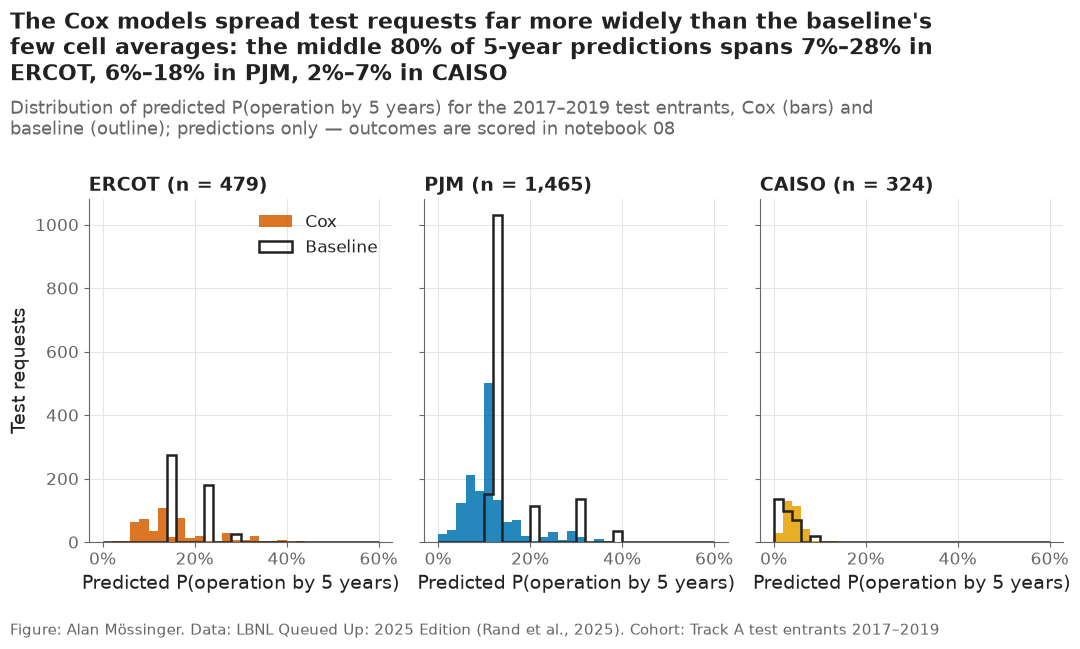

cox_3  cox_5  cox_7  baseline_3  baseline_5  baseline_7
split      region                                                         
test       CAISO   0.023  0.042  0.064       0.008       0.021       0.053
           ERCOT   0.095  0.153  0.196       0.090       0.183       0.230
           PJM     0.068  0.114  0.154       0.100       0.159       0.203
validation CAISO   0.033  0.061  0.089       0.007       0.032       0.072
           ERCOT   0.076  0.126  0.167       0.100       0.197       0.245
           PJM     0.093  0.154  0.200       0.111       0.176       0.223

In [13]:
targets = pd.concat([valid, test])
baseline_pred = survival_tools.baseline_cif(final, targets, HORIZONS)
cox_pred = survival_tools.cause_specific_cif(models["operation"], models["withdrawal"],
                                             survival_tools.cox_design(targets), HORIZONS)
predictions = pd.DataFrame({"project_key": targets["project_key"], "region": targets["region"],
                            "q_year": targets["q_year"], "split": np.where(targets["q_year"] == config.VALIDATION_YEAR,
                                                                           "validation", "test"),
                            "baseline_cell": baseline_pred["cell"]}, index=targets.index)
for h in HORIZONS:
    predictions[f"baseline_{h}"] = baseline_pred[h]
    predictions[f"cox_{h}"] = cox_pred[h]
predictions.to_parquet(paths.DATA_INTERIM / "predictions_05.parquet")

test_pred = predictions[predictions["split"] == "test"]
fig, axes = plt.subplots(1, 3, sharey=True)
bins = np.linspace(0, 0.6, 31)
for ax, region in zip(axes, TRACK_A):
    part = test_pred[test_pred["region"] == region]
    ax.hist(part["cox_5"], bins=bins, color=plots.region_color(region), alpha=0.85, label="Cox")
    ax.hist(part["baseline_5"], bins=bins, histtype="step", color=plots.INK, linewidth=1.8, label="Baseline")
    ax.set_title(f"{region} (n = {len(part):,})")
    ax.set_xlabel("Predicted P(operation by 5 years)")
    ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
axes[0].set_ylabel("Test requests")
axes[0].legend(loc="upper right")
spread = test_pred.groupby("region")["cox_5"].quantile([0.1, 0.9]).unstack()
plots.finish(fig,
             "The Cox models spread test requests far more widely than the baseline's few cell averages: the middle "
             "80% of 5-year predictions spans " + ", ".join(
                 f"{spread.loc[r, 0.1]:.0%}–{spread.loc[r, 0.9]:.0%} in {r}" for r in TRACK_A),
             "Distribution of predicted P(operation by 5 years) for the 2017–2019 test entrants, Cox (bars) and baseline "
             "(outline); predictions only — outcomes are scored in notebook 08",
             "Track A test entrants 2017–2019")
save(fig, "05_08_test_prediction_spread", "Distribution of 5-year predictions for the test entrants, Cox models versus baseline.")
plt.show()
predictions.groupby(["split", "region"])[[f"cox_{h}" for h in HORIZONS] + [f"baseline_{h}" for h in HORIZONS]].mean().round(3)

**Reading this.** Predictions exist for all 573 validation and 2,268 test requests at 3, 5 and 7 years. The Cox models spread test requests much more widely than the baseline's handful of cell averages: the middle 80% of five-year predictions spans 7%–28% in ERCOT, 6%–18% in PJM and 2%–7% in CAISO. On average the Cox predictions for the test cohort are lower than the baseline's in ERCOT (15.3% vs 18.3% at five years) and PJM (11.4% vs 15.9%) and higher in CAISO (4.2% vs 2.1%). No test outcome has been looked at.

## 11. Checks

In [14]:
figure_files = [paths.FIGURES / NOTEBOOK / f"diag_schoenfeld_{c}.png" for c in CAUSES]
checks = pd.DataFrame([
    ("region hazard ratios for operation in the expected order (ERCOT > PJM > CAISO)",
     bool(sign_checks["passed"].iloc[:2].all())),
    ("requests of 20 MW or more slower than smaller ones (operation)", bool(sign_checks["passed"].iloc[2:].all())),
    ("PH diagnostics saved (tests and Schoenfeld plots)",
     (paths.RESULTS / "cox_ph_tests.csv").exists() and all(f.exists() for f in figure_files)),
    ("hazard-ratio table has HR, 95% CI and p for both causes",
     set(hazard_ratios["cause"]) == set(CAUSES) and hazard_ratios[["ci_low", "ci_high", "p"]].notna().all().all()),
    ("predictions for every validation and test request at 3/5/7 years",
     bool(predictions[[f"cox_{h}" for h in HORIZONS]].notna().all().all()) and len(predictions) == len(targets)),
], columns=["check", "passed"])
checks["result"] = np.where(checks["passed"], "PASS", "FAIL")
checks.to_csv(paths.RESULTS / "cox_checks.csv", index=False)
checks[["check", "result"]]

,check,result
0,region hazard ratios for operation in the expe...,PASS
1,requests of 20 MW or more slower than smaller ...,PASS
2,PH diagnostics saved (tests and Schoenfeld plots),PASS
3,"hazard-ratio table has HR, 95% CI and p for bo...",PASS
4,predictions for every validation and test requ...,PASS


**Reading this.** All five checks pass: the region hazard ratios are in the expected order, small requests are faster, the PH diagnostics are saved (tests in `results/cox_ph_tests.csv`, Schoenfeld plots as `diag_schoenfeld_*`), the hazard-ratio table has estimates, intervals and p-values for both causes, and every validation and test request has a prediction.

## Takeaways

- The baseline (region × technology completion rates, 3.5%–42.8% by seven years) is a strong benchmark: it was closer than the Cox models to the average outcome of the 2016 cohort (2.6 vs 3.9 points).
- Cox hazard ratios for operation, other things equal: ERCOT 1.66× and CAISO 0.52× PJM; gas 2.56× and "Other" 1.74× solar; under 5 MW 1.85× and 500 MW and up 0.31× the 20–100 MW class; each later 5 years of request 0.84×. Withdrawal is much less predictable from entry-time attributes.
- Proportional hazards fails for 17 of 36 effects: fast profiles (gas, small) are fast early and the advantage fades after about six years. This is the case for the discrete-time models of notebook 06.
- Delayed entry for ERCOT drops 607 of its 732 training requests (176 completions) from the fits; the ERCOT effect is the one estimate that depends strongly on the treatment (1.66 vs 0.64 as recorded).

**What goes to the report:** the hazard-ratio table (via F6 in notebook 09), one sentence each on the PH drift (diag_schoenfeld_operation) and on the ERCOT sensitivity (05_05), and 05_07 as the plain-language example for developers.